In [1]:
import numpy as np

data = np.load('../../data/processed/dataset_preprocessed.npz')
x = data['X_data']
y = data['Y_data']

In [2]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

### Tesorflow's Functional API

In [3]:
from tensorflow.keras import layers, Model

max_length = 25

inputs = layers.Input(shape=(max_length, 250))

x = layers.SimpleRNN(units=32)(inputs)

outputs = layers.Dense(1, activation='sigmoid')(x)

model = Model(inputs=inputs, outputs=outputs, name="Simple_RNN_Sentiment")

model.summary()

Model: "Simple_RNN_Sentiment"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 25, 250)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         9,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,089 (35.50 KB)

 Trainable params: 9,089 (35.50 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    x_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/50


W0000 00:00:1790259646.297469   98838 cpu_allocator_impl.cc:82] Allocation of 121800000 exceeds 10% of free system memory.


148/153 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7149 - loss: 0.5625

W0000 00:00:1790259651.048254   98838 cpu_allocator_impl.cc:82] Allocation of 30450000 exceeds 10% of free system memory.


153/153 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.7157 - loss: 0.5613 - val_accuracy: 0.7307 - val_loss: 0.5495
Epoch 2/50
153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7713 - loss: 0.4945 - val_accuracy: 0.7397 - val_loss: 0.5439
Epoch 3/50
153/153 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.7816 - loss: 0.4812 - val_accuracy: 0.7447 - val_loss: 0.5440
Epoch 4/50
153/153 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.7890 - loss: 0.4550 - val_accuracy: 0.7397 - val_loss: 0.5638
Epoch 5/50
153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8048 - loss: 0.4411 - val_accuracy: 0.7323 - val_loss: 0.5498
Epoch 6/50
153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8151 - loss: 0.4236 - val_accuracy: 0.7340 - val_loss: 0.5676
Epoch 7/50
153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8136 - loss: 0.4113 - val_accuracy: 0.7496 - val_loss: 0.5769
Epoch 8/50
153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8303 - loss: 0.3948 - val_accuracy: 0.7455 - va

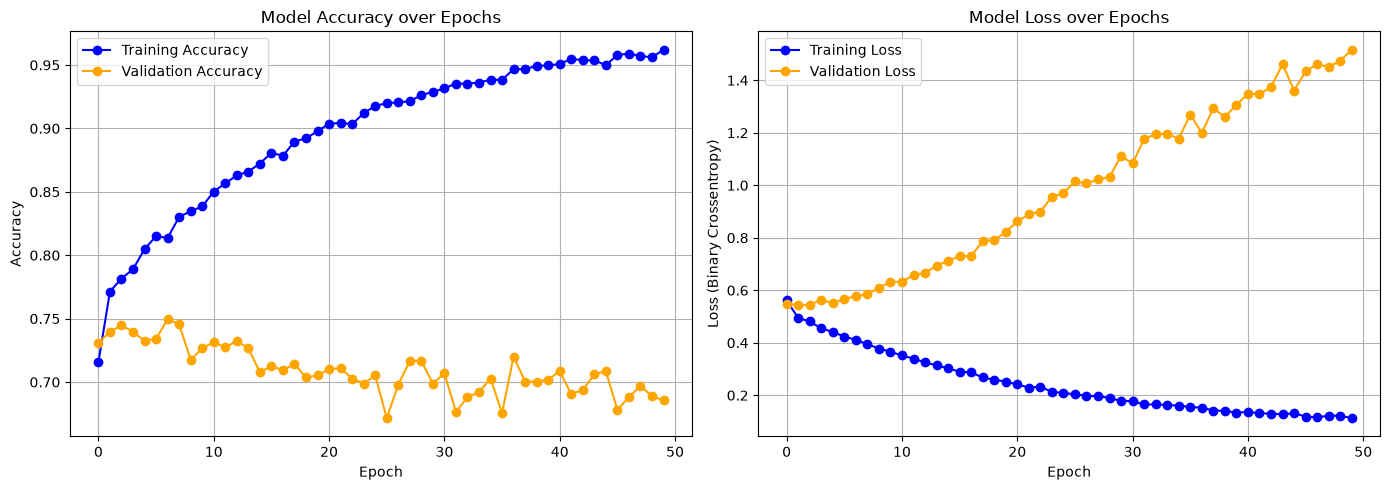

W0000 00:00:1790260174.284111   98838 cpu_allocator_impl.cc:82] Allocation of 30450000 exceeds 10% of free system memory.


39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step


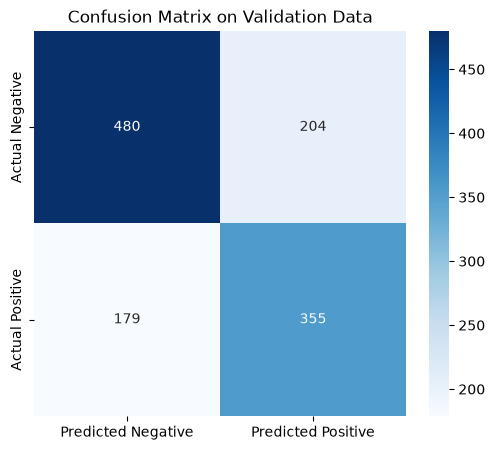

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# 1. Plot Accuracy and Loss over Epochs
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Plot
ax1.plot(history.history['accuracy'], label='Training Accuracy', color='blue', marker='o')
ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange', marker='o')
ax1.set_title('Model Accuracy over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

# Loss Plot
ax2.plot(history.history['loss'], label='Training Loss', color='blue', marker='o')
ax2.plot(history.history['val_loss'], label='Validation Loss', color='orange', marker='o')
ax2.set_title('Model Loss over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss (Binary Crossentropy)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

# 2. Generate a Confusion Matrix
# We use the final 20% of the data as a proxy for our validation set to match the validation_split
val_split_index = int(len(x_train) * 0.8)
X_val = x_train[val_split_index:]
Y_val = y_train[val_split_index:]

# Get raw probability predictions from the model
predictions_prob = model.predict(X_val)

# Convert probabilities to binary classes (0 or 1) using a 0.5 threshold
predictions_binary = (predictions_prob > 0.5).astype(int)

# Calculate the confusion matrix
cm = confusion_matrix(Y_val, predictions_binary)

# Plot the confusion matrix using Seaborn
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Predicted Negative', 'Predicted Positive'],
            yticklabels=['Actual Negative', 'Actual Positive'])
plt.title('Confusion Matrix on Validation Data')
plt.show()

## Conclusion

Using a simple RNN model works but the model overfit.